In [1]:
import torch 
pred = torch.tensor([[[0.1, 0.2], [0.3, 0.4]], [[0.5, 0.6], [0.7, 0.8]]], dtype=torch.float32)
target = torch.tensor([[[0.1, 0.25], [0.35, 0.45]], [[0.55, 0.65], [0.75, 0.85]]], dtype=torch.float32)
mask = torch.tensor([[[1, 0], [1, 1]], [[0, 1], [1, 1]]], dtype=torch.float32)


In [2]:
# import torch
# import torch.nn as nn
# import numpy as np

# def dice_loss(input, target):
#     """
#     Compute the Dice loss between the input and target.
    
#     Args:
#         input (torch.Tensor): The input tensor, typically the output of a neural network.
#         target (torch.Tensor): The target tensor, typically the ground truth.
        
#     Returns:
#         torch.Tensor: The Dice loss.
#     """
#     smooth = 1.0
#     input_flat = input.view(-1)
#     target_flat = target.view(-1)
#     intersection = (input_flat * target_flat).sum()
#     loss = 1 - ((2.0 * intersection + smooth) / (input_flat.sum() + target_flat.sum() + smooth))
#     return loss

Starting to load the biomass data
Load complete
Original shape: (326, 840)
Cropped shape: (321, 665)
665 665
Quadrant shape: torch.Size([160, 332, 36, 1]) -> torch.Size([160, 352, 36, 1])
Ground truth shape: torch.Size([160, 332]) -> torch.Size([160, 352])
Quadrant shape: torch.Size([160, 333, 36, 1]) -> torch.Size([160, 352, 36, 1])
Ground truth shape: torch.Size([160, 333]) -> torch.Size([160, 352])
Quadrant shape: torch.Size([161, 332, 36, 1]) -> torch.Size([192, 352, 36, 1])
Ground truth shape: torch.Size([161, 332]) -> torch.Size([192, 352])
Quadrant shape: torch.Size([161, 333, 36, 1]) -> torch.Size([192, 352, 36, 1])
Ground truth shape: torch.Size([161, 333]) -> torch.Size([192, 352])
Total valid patches: 116
Quadrant 0: 25 valid patches
Quadrant 1: 40 valid patches
Quadrant 2: 27 valid patches
Quadrant 3: 24 valid patches
Dataset Initialization Information:
Patch size: (64, 64, 36)
Stride: (32, 32, 36)

Quadrant 0:
  Original shape: torch.Size([160, 332, 36, 1])
  Padded shape:

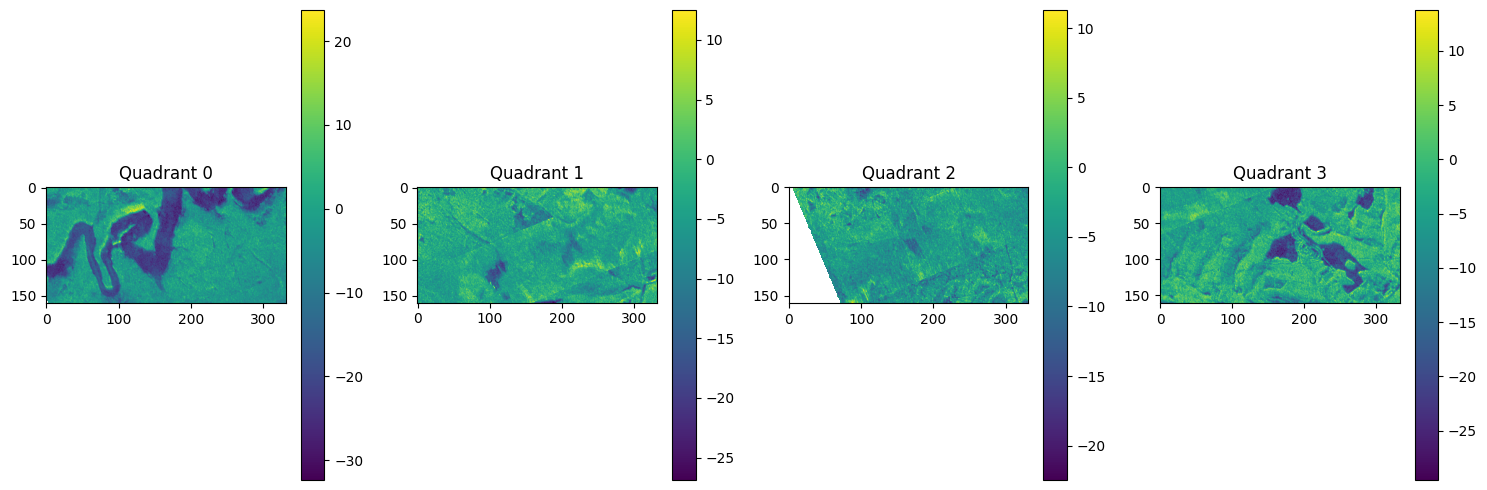

In [10]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import sys 
sys.path.append('/home/grace.bcolverd/2024-ESL-BiomassSAR')
from src.fdlbiomass.quadrant_dataset_pband import QuadrantPatchDataset

import numpy as np
import torch
import matplotlib.pyplot as plt
from src.fdlbiomass.utils import merge_headings, load_biomass_data, split_into_quadrants, crop_to_non_nan
from src.fdlbiomass.quadrant_dataset_pband import QuadrantPatchDataset
from torch.utils.data import DataLoader
from src.fdlbiomass.dataloader_fns import generate_quadrants, generate_dataloaders
from src.fdlbiomass.simple_conv import SimpleConv3D
from src.fdlbiomass.quadrant_dataset_pband import QuadrantPatchDataset 


# Assuming the necessary imports from your scripts

parent_path = '/home/grace.bcolverd/esl_dev/tomosar-matlab'
polarimetric_channels = 'HH'
patch_size = (64, 64, 36)
stride = (32, 32, 36)
test_quadrant = 3
batch_size = 20
scaler_type = 'standard'

quadrants, ground_truths, num_channels = generate_quadrants(parent_path, polarimetric_channels)

# 2. Create dataset and dataloaders
train_loader, test_loader, val_loader, dataset, (input_scaler, gt_scaler), val_quad = generate_dataloaders(
    quadrants, ground_truths, patch_size, stride, test_quadrant, batch_size, scaler_type
)

# 3. Visualize original data
plt.figure(figsize=(15, 5))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(quadrants[i][:,:,0,0])  # Assuming first channel, first depth slice
    plt.title(f"Quadrant {i}")
    plt.colorbar()
plt.tight_layout()
plt.show()

In [12]:
for batch_idx, (batch_input, batch_target, mask) in enumerate(val_loader):
    # print(batch_input.shape)
    print(mask.shape)

torch.Size([20, 64, 64])
torch.Size([7, 64, 64])


In [24]:
# create dummy pred and target of same shape 
target = torch.rand(mask.shape, dtype=float)
pred = target.clone()
mask.shape == pred.shape

True

In [96]:
import torch

def dice_loss(pred, target):
    """
    Compute the Dice loss between the prediction and target.
    
    Args:
        pred (torch.Tensor): The prediction tensor. Shape: (batch_size, 1, height, width)
        target (torch.Tensor): The target tensor (ground truth). Shape: (batch_size, 1, height, width)
        
    Returns:
        torch.Tensor: The Dice loss.
    """
    smooth = 1.0
    
    # Flatten the prediction and target tensors
    pred_flat = pred.view(-1)
    target_flat = target.view(-1)
    
    # Calculate the intersection and union
    intersection = (pred_flat * target_flat).sum()
    union = pred_flat.sum() + target_flat.sum()
    
    # Compute the Dice coefficient
    
    
    # Compute the Dice loss
    dice_loss = 1 - (2 * intersection / (pred_flat.sum() + target_flat.sum()))
    
    return dice_loss

In [97]:

# Generate sample input, target, and mask tensors
batch_size = 7
height, width = 64, 64
input_tensor = torch.rand(batch_size, height, width)
# target_tensor = torch.randint(0, 2, (batch_size, 1, height, width))
target_tensor = input_tensor.clone() 
mask_tensor = torch.ones((batch_size, height, width), dtype=torch.bool)


dice_loss(input_tensor, input_tensor)

tensor(0.3331)

In [108]:
mask_all_zeros = torch.zeros_like(mask, dtype=torch.bool)
mask_all_zeros

tensor([[[False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         ...,
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False]],

        [[False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         ...,
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False]],

        [[False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         ...,
         [False, False, False,  ..., False, False, False],
         [

In [109]:
torch.all(~mask_all_zeros)

tensor(True)

In [103]:
def dice_loss(pred, target):
    """This definition generalize to real valued pred and target vector.
    This should be differentiable.
    pred: tensor with first dimension as batch
    target: tensor with first dimension as batch
    """

    smooth = 1.

    # have to use contiguous since they may from a torch.view op
    iflat = pred.contiguous().view(-1)
    tflat = target.contiguous().view(-1)
    intersection = (iflat * tflat).sum()

    A_sum = torch.sum(tflat * iflat)
    B_sum = torch.sum(tflat * tflat)
    
    return 1 - ((2. * intersection + smooth) / (A_sum + B_sum + smooth) )

In [104]:
def mask_dice_loss(pred, target, mask ):
    """This definition generalize to real valued pred and target vector.
    This should be differentiable.
    pred: tensor with first dimension as batch
    target: tensor with first dimension as batch
    """
    pred = pred[mask]
    target=target[mask]

    smooth = 1.

    # have to use contiguous since they may from a torch.view op
    iflat = pred.contiguous().view(-1)
    tflat = target.contiguous().view(-1)
    intersection = (iflat * tflat).sum()

    A_sum = torch.sum(tflat * iflat)
    B_sum = torch.sum(tflat * tflat)
    
    return 1 - ((2. * intersection + smooth) / (A_sum + B_sum + smooth) )

In [107]:
import torch

# Generate sample input, target, and mask tensors
batch_size = 7
height, width = 64, 64
input_tensor = torch.rand(batch_size, height, width)
target_tensor = torch.randint(0, 2, (batch_size,  height, width))

mask_tensor = torch.ones((batch_size, height, width), dtype=torch.bool)

mask_dice_loss(input_tensor, target_tensor, mask)

tensor(0.3348)

In [100]:
import torch

# Generate some sample input and target tensors
batch_size = 4
height, width = 64, 64
input_tensor = torch.rand(batch_size, 1, height, width)

# Compute the Dice loss
loss = dice_loss(input_tensor, input_tensor)
print(f"Dice loss: {loss.item()}")

Dice loss: 0.0


In [91]:
input_tensor - target_tensor

tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]],

        [[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]],

        [[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]],

        ...,

        [[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0., 

tensor(27438.5337, dtype=torch.float64)


tensor(0.6674, dtype=torch.float64)

0
Dice loss: 0.3320397734642029
1
Dice loss: 0.32899922132492065
2
Dice loss: 0.33446449041366577
3
Dice loss: 0.33055078983306885
4
Dice loss: 0.34001481533050537
5
Dice loss: 0.3380158543586731
6
Dice loss: 0.32844603061676025


In [86]:
target_mask.shape

torch.Size([64, 64])

In [65]:
dice = 1- ( 2 * (input_tensor *target_tensor ).sum() / (input_tensor.sum() + target_tensor.sum() ))
dice

tensor(0.3341)

In [66]:
input_tensor.shape

torch.Size([7, 1, 64, 64])

In [ ]:
import torch

def dice_loss_with_mask(input, target, mask):
    """
    Compute the Dice loss between the input and target, with a mask.
    
    Args:
        input (torch.Tensor): The input tensor, typically the output of a neural network. Shape: (batch_size, 1, height, width)
        target (torch.Tensor): The target tensor, typically the ground truth. Shape: (batch_size, 1, height, width)
        mask (torch.Tensor): The mask tensor, with 1 indicating valid regions and 0 indicating invalid regions. Shape: (batch_size, height, width)
        
    Returns:
        torch.Tensor: The Dice loss.
    """
    smooth = 1.0
    batch_size = input.size(0)
    height, width = input.size(2), input.size(3)
    loss = 0.0

    for b in range(batch_size):
        input_flat = input[b, 0].view(-1)
        target_flat = target[b, 0].view(-1)
        mask_flat = mask[b].view(-1).bool()
        
        # Apply the mask to the input and target tensors
        input_masked = input_flat[mask_flat]
        target_masked = target_flat[mask_flat]
        
        intersection = (input_masked * target_masked).sum()
        union = input_masked.sum() + target_masked.sum()
        dice_loss = 1 - ((2.0 * intersection + smooth) / (union + smooth))
        loss += dice_loss

    return loss / batch_size

In [73]:
torch.zeros(mask.shape).shape[1] * torch.zeros(mask.shape).shape[2]

4096

In [57]:
summ

tensor(27438.5337, dtype=torch.float64)

In [56]:
intersec  = pred_mask * target_mask 
inff = 2 * intersec.sum()
inff


tensor(18311.6451, dtype=torch.float64)

In [8]:
import torch

def dice_loss_with_mask(input, target, mask):
    """
    Compute the Dice loss between the input and target, with a mask.
    
    Args:
        input (torch.Tensor): The input tensor, typically the output of a neural network.
        target (torch.Tensor): The target tensor, typically the ground truth.
        mask (torch.Tensor): The mask tensor, with True indicating valid regions and False indicating invalid regions.
        
    Returns:
        torch.Tensor: The Dice loss.
    """
    smooth = 1.0
    input_flat = input.view(-1)
    target_flat = target.view(-1)
    mask_flat = mask.view(-1)
    
    # Apply the mask to the input and target tensors
    input_flat = input_flat[mask_flat]
    target_flat = target_flat[mask_flat]
    
    intersection = (input_flat * target_flat).sum()
    union = 
    loss = 1 - ((2.0 * intersection + smooth) / (input_flat.sum() + target_flat.sum() + smooth))
    return loss

In [74]:
smooth = 1.0
input_flat = input.view(-1)
target_flat = target.view(-1)
mask_flat = mask.view(-1)

# Apply the mask to the input and target tensors
input_flat = input_flat[mask_flat]
target_flat = target_flat[mask_flat]


AttributeError: 'function' object has no attribute 'view'

In [ ]:

intersection = (input_flat * target_flat).sum()
union = 
loss = 1 - ((2.0 * intersection + smooth) / (input_flat.sum() + target_flat.sum() + smooth))

Dice loss: 0.4871114492416382


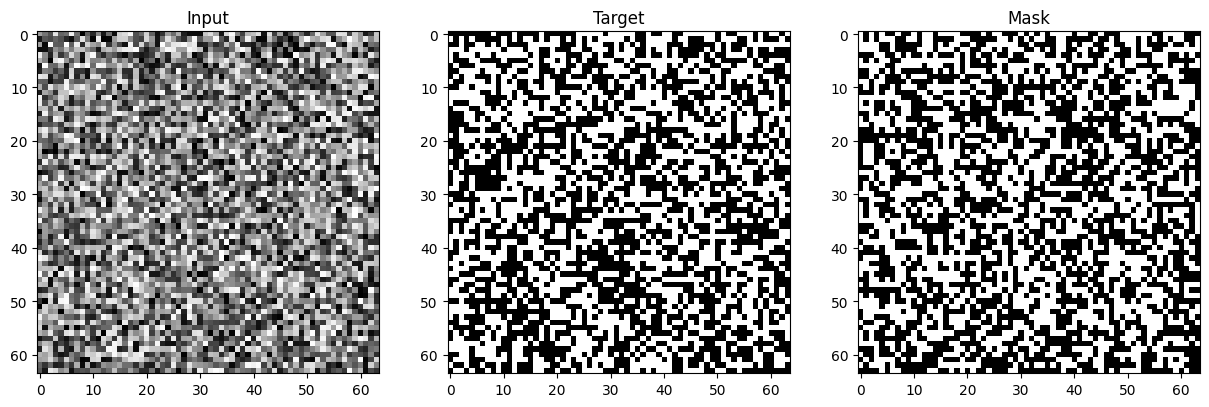

In [6]:
import torch

# Generate some random input, target, and mask tensors
input_tensor = torch.rand(1, 1, 64, 64)
target_tensor = torch.randint(0, 2, (1, 1, 64, 64))
mask_tensor = torch.randint(0, 2, (1, 1, 64, 64))

# Compute the Dice loss with a mask
loss = dice_loss_with_mask(input_tensor, target_tensor, mask_tensor)
print(f"Dice loss: {loss.item()}")

# Visualize the input, target, and mask tensors
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

ax1.imshow(input_tensor[0, 0].detach().cpu().numpy(), cmap='gray')
ax1.set_title('Input')

ax2.imshow(target_tensor[0, 0].detach().cpu().numpy(), cmap='gray')
ax2.set_title('Target')

ax3.imshow(mask_tensor[0, 0].detach().cpu().numpy(), cmap='gray')
ax3.set_title('Mask')

plt.show()

Dice loss: 0.0


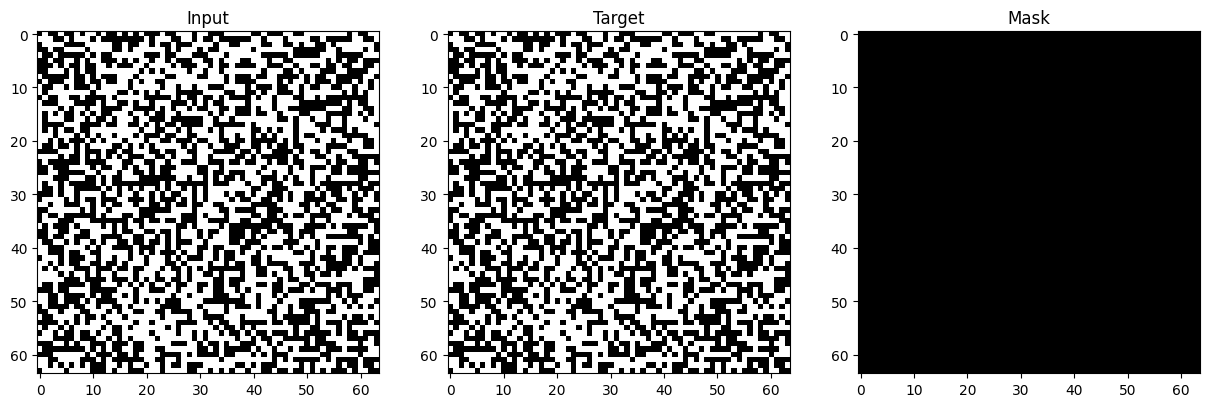

In [7]:
import torch

# Generate some random input and target tensors, with a mask
input_tensor = torch.randint(0, 2, (1, 1, 64, 64)).float()
target_tensor = input_tensor.clone()
mask_tensor = torch.ones(1, 1, 64, 64)

# Compute the Dice loss with a mask
loss = dice_loss_with_mask(input_tensor, target_tensor, mask_tensor)
print(f"Dice loss: {loss.item()}")

# Visualize the input, target, and mask tensors
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

ax1.imshow(input_tensor[0, 0].detach().cpu().numpy(), cmap='gray')
ax1.set_title('Input')

ax2.imshow(target_tensor[0, 0].detach().cpu().numpy(), cmap='gray')
ax2.set_title('Target')

ax3.imshow(mask_tensor[0, 0].detach().cpu().numpy(), cmap='gray')
ax3.set_title('Mask')

plt.show()

Dice loss: 0.0


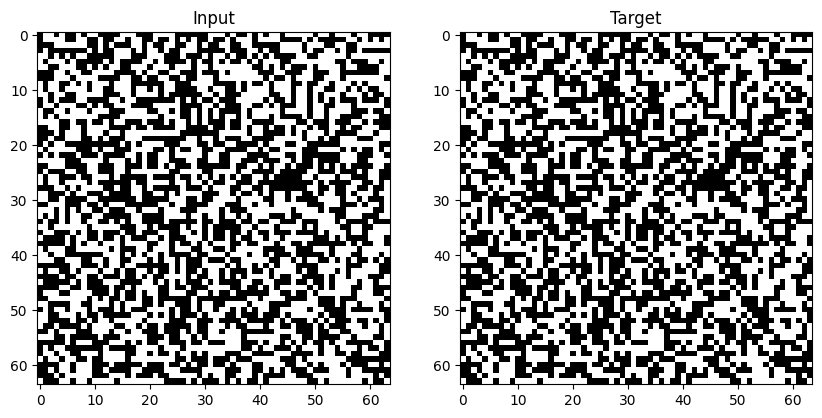

In [4]:
import torch

# Generate some random input and target tensors
input_tensor = torch.randint(0, 2, (1, 1, 64, 64)).float()
target_tensor = input_tensor.clone()

# Compute the Dice loss
loss = dice_loss(input_tensor, target_tensor)
print(f"Dice loss: {loss.item()}")

# Visualize the input and target tensors
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.imshow(input_tensor[0, 0].detach().cpu().numpy(), cmap='gray')
ax1.set_title('Input')

ax2.imshow(target_tensor[0, 0].detach().cpu().numpy(), cmap='gray')
ax2.set_title('Target')

plt.show()

In [ ]:
def masked_dice_loss(pred, target, mask, smooth=1e-7):
    if pred.dim() != 3 or target.dim() != 3 or mask.dim() != 3:
        raise ValueError(f"All inputs must be 3D tensors. Got shapes: pred {pred.shape}, target {target.shape}, mask {mask.shape}")
    
    if pred.shape != target.shape or pred.shape != mask.shape:
        raise ValueError(f"All inputs must have the same shape. Got shapes: pred {pred.shape}, target {target.shape}, mask {mask.shape}")

    pred = pred.contiguous()
    target = target.contiguous()
    mask = mask.contiguous()
    
    # Apply mask
    pred = pred * mask
    target = target * mask
    
    # Flatten the tensors
    pred = pred.view(-1)
    target = target.view(-1)
    mask = mask.view(-1)
    
    # Calculate intersection and sums
    intersection = (pred * target).sum()
    pred_sum = pred.sum()
    target_sum = target.sum()
    
    # Calculate Dice coefficient
    dice = (2. * intersection + smooth) / (pred_sum + target_sum + smooth)
    loss = 1 - dice

    # Debugging information
    debug_info = {
        "intersection": intersection.item(),
        "pred_sum": pred_sum.item(),
        "target_sum": target_sum.item(),
        "dice": dice.item(),
        "loss": loss.item(),
        "num_masked_elements": mask.sum().item()
    }
    
    return loss, debug_info

: 